# Homework 2: Programming

The following notebook contains skeleton-code for answering problems 2 and 3 of homework assignment 2. Please read through each cell carefully to understand what is expected to be implemented. For your final submission, please try to clean up any intermediate outputs used for debugging.

### Imports

You should be able to complete the entire assignment using only the following imports. Please consult the course staff if you are unsure about whether additional packages may be used.

In [1]:
## Import Packages
import random
import numpy as np
import matplotlib.pyplot as plt

## Question 2


Below we provide an AutoGrad class named `Value`. The basic idea is to store the existing computational map during the creation of each `Value`, and calculate the gradient using backpropagation when one of the `Value` calls `backward()` method.

The `backward()` function will arange the computational graph and backpropagate the gradients. All you need to do is to implement all the operations with its corresponding `_backward` function. We have provided the `__add__` function (sum of two nodes) as an example to help get you started.

This notebook is designed in a Object Oriented way, if you are not farmiliar with the Object Oriented Programming in Python, you can refer to:

(1) https://realpython.com/python3-object-oriented-programming/

(2) https://docs.python.org/3/tutorial/classes.html


In [2]:
class Value:

    """
    Basic unit of storing a single scalar value and its gradient
    """

    def __init__(self, data, _children=()):
        """

        """
        self.data = data
        self.grad = 0
        self._prev = set(_children)
        self._backward = lambda: None

    def __add__(self, other):
        """
        Example implementation of a single class operation (addition)

        Args:
            other (Any): Node to add with the class

        Returns:
            out (callable): Function to referesh the gradient
        """
        #Firstly, convert some default value type in python to Value
        #Then do operations with two or more Value object
        other = other if isinstance(other, Value) else Value(other)

        #Secondly, create a new Value object which is the result of the operation
        out = Value(self.data + other.data, (self, other))

        #Thirdly, create a _backward function for the output object to refresh
        # the gradient of its _childrens,
        #Then assign this _backward function to the output object.
        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward

        return out

    def __mul__(self, other):
        """
        Multiplication operation (e.g. Value(3) * Value(2) = Value(6))
        """
        
        other = other if isinstance(other, Value) else Value(other)

        out = Value (self.data * other.data, (self, other))
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        
        out._backward = _backward

        return out

    def __pow__(self, other):
        """
        Power operation (e.g Value(3) ** 2 = Value(9))
        """
        
        assert isinstance(other, (int, float))
        
        out = Value (self.data ** other, (self,))
        
        def _backward():
            if other != 0:
                self.grad += other * self.data ** (other - 1) * out.grad

        out._backward = _backward
        return out

    def relu(self):
        """
        ReLU activation function applied to the current Value
        """
        out = Value(max(0, self.data), (self,))

        def _backward():
            self.grad += (self.data > 0) * out.grad

        out._backward = _backward
        return out


    def exp(self):
        """
        Exponentiate the current Value (e.g. e ^ Value(0) = Value(1))
        """
        out = Value(np.exp(self.data), (self,))

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward
        return out

    def log(self):
        """
        Take the natural logarithm (base e) of the current Value
        """
        out = Value(np.log(self.data), (self,))

        def _backward():
            self.grad += (1 / self.data) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        """
        Run backpropagation from the current Value
        """
        #This function is called when you start backpropagation from this Value

        #The gradient of this value is initialized to 1 for you.
        self.grad = 1

        #You need to find a right topological order all of the children in the graph.
        #As for topology sort, you can refer to http://www.cs.cornell.edu/courses/cs312/2004fa/lectures/lecture15.htm
        topo = []
        visited = set()

        def build_topo(node):
            if node not in visited:
                visited.add(node)
                for child in node._prev:
                    build_topo(child)
                topo.append(node)

        build_topo(self)
        topo.reverse()

        '''
        Hint: you can recursively visit all non-visited node from the node calling backward.
        add one node to the head of the list after all of its children node are visited
        '''

        #go one variable at a time and apply the chain rule to get its gradient

        for v in topo:
            v._backward()

    # We handled the negation and reverse operations for you
    def __neg__(self): # -self
        """
        Negate the current Value
        """
        return self * -1

    def __radd__(self, other): #other + self
        """
        Reverse addition operation (ordering matters in Python)
        """
        return self + other

    def __sub__(self, other): # self - other
        """
        Subtraction operation
        """
        return self + (-other)

    def __rsub__(self, other): # other - self
        """
        Reverse subtraction operation
        """
        return other + (-self)

    def __rmul__(self, other): # other * self
        """
        Reverse multiplication operation
        """
        return self * other

    def __truediv__(self, other): # self / other
        """
        Division operation
        """
        return self * other**-1

    def __rtruediv__(self, other): # other / self
        """
        Reverse diction operation
        """
        return other * self**-1

    def __repr__(self):
        """
        Class representation (instead of unfriendly memory address)
        """
        return f"Value(data={self.data}, grad={self.grad})"

Now, we are going to use the simple example in q1.b to get you familar with the usage of this class.

If your implementation is correct, you will get the same values and gradients as your hand-caculated ones.

Be careful! Even you get this test case right, it does not guarantee the correctness of your implementation.

In [3]:
## Initialize Example Values (From Written Assignment)
w1 = Value(0.2)
w2 = Value(0.4)
x1 = Value(-0.4)
x2 = Value(0.5)
#Do calculation for the question 1.b, and call backward to start backpropagation.
#Then print out the gradient of w1 w2 x1 x2.

#Forward pass
a = w1 * x1
c = w2 * x2
e = a + c
neg_e = -e
exp_neg_e = neg_e.exp()
denominator = 1 + exp_neg_e
z = 1 / denominator

b = w1 ** 2
d = w2 ** 2
g = b + d
i = 0.5 * g
f = z + i

#Names and nodes for printing
intermediates = [
    ("w1 * x1", a),
    ("w2 * x2", c),
    ("w1*x1 + w2*x2", e),
    ("-e", neg_e),
    ("exp(-e)", exp_neg_e),
    ("1 + exp(-e)", denominator),
    ("sigmoid", z),
    ("w1^2", b),
    ("w2^2", d),
    ("w1^2 + w2^2", g),
    ("regularization", i),
    ("result", f),
]

print("Forward Pass:")
for name, node in intermediates:
    print(f"{name} = {node.data:.4f}")

# Backward pass
f.backward()

print("\nBackward Pass:")
inputs = [("w1", w1), ("w2", w2), ("x1", x1), ("x2", x2)]

for name, node in inputs + intermediates:
    print(f"grad {name} = {node.grad:.4f}")

Forward Pass:
w1 * x1 = -0.0800
w2 * x2 = 0.2000
w1*x1 + w2*x2 = 0.1200
-e = -0.1200
exp(-e) = 0.8869
1 + exp(-e) = 1.8869
sigmoid = 0.5300
w1^2 = 0.0400
w2^2 = 0.1600
w1^2 + w2^2 = 0.2000
regularization = 0.1000
result = 0.6300

Backward Pass:
grad w1 = 0.1004
grad w2 = 0.5246
grad x1 = 0.0498
grad x2 = 0.0996
grad w1 * x1 = 0.2491
grad w2 * x2 = 0.2491
grad w1*x1 + w2*x2 = 0.2491
grad -e = -0.2491
grad exp(-e) = -0.2809
grad 1 + exp(-e) = -0.2809
grad sigmoid = 1.0000
grad w1^2 = 0.5000
grad w2^2 = 0.5000
grad w1^2 + w2^2 = 0.5000
grad regularization = 1.0000
grad result = 1.0000


## Question 3

### Implementation of the linear layer
You will implement a `LinearLayer` module here.

We provide the initialization of the class `LinearLayer`. You need to implement the forward function -- Return the results - `out` with the shape `[n_samples, n_out_channels]` of a linear layer when the the data `x` shaped `[n_samples, n_in_channels]` is fed into it.


In [5]:
class Module:

    """
    Base Model Module
    """

    def parameters(self):
        """

        """
        return []

    def zero_grad(self):
        """

        """
        for p in self.parameters():
            p.grad = 0

class LinearLayer(Module):

    """
    Linear Layer
    """

    def __init__(self, nin, nout):
        """
        Here we randomly initilize the weights w as 2-dimensional list of Values
        And b as 1-dimensional list of Values with value 0

        You may use this stucture to implement the __call__ function
        """
        self.w = []
        for i in range(nin):
            w_tmp = [Value(random.uniform(-0.01, 0.01)) for j in range(nout)]
            self.w.append(w_tmp)
        self.b = [Value(0) for i in range(nout)]
        self.nin = nin
        self.nout = nout

    def __call__(self, x):
        """
        Args:
            x (2d-list): Two dimensional list of Values with shape [batch_size , nin]

        Returns:
            xout (2d-list): Two dimensional list of Values with shape [batch_size, nout]
        """
        xout = []

        for sample in x:
            row = []
            for j in range(self.nout):
                total = self.b[j]
                for i in range(self.nin):
                    total = total + sample[i] * self.w[i][j]
                row.append(total)
            xout.append(row)

        return xout

    def parameters(self):
        """
        Get the list of parameters in the Linear Layer

        Args:
            None

        Returns:
            params (list): List of parameters in the layer
        """
        return [p for row in self.w for p in row] + [p for p in self.b]

Test your implementation of linear layer, the error should be nearly 0.

In [6]:
## Initialization of Layer with Weights
linear_model_test = LinearLayer(4, 4)
linear_model_test.w = [[Value(data=0.7433570245252463), Value(data=-0.9662164096144394), Value(data=-0.17087204941322653), Value(data=-0.5186656374983067)],
                       [Value(data=-0.1414882837892344), Value(data=-0.5898971049017006), Value(data=-0.3448340220492381), Value(data=0.5278833226346107)],
                       [Value(data=0.3990701306597799), Value(data=-0.3319058654296163), Value(data=-0.784797384411202), Value(data=0.7603317495966846)],
                       [Value(data=-0.5711035064293541), Value(data=-0.0001937643033362857), Value(data=0.12693226232877053), Value(data=-0.36044237239197097)]]
linear_model_test.b = [Value(data=0), Value(data=0), Value(data=0), Value(data=0)]

## Forward Pass
x_test = [[-0.17120438454836173, -0.3736077734087335, -0.48495413054653214, 0.8269206715993096]]
y_hat_test = linear_model_test(x_test)
y_ref = [[Value(data=-0.7401928625441141), Value(data=0.5466095223360173), Value(data=0.6436403600545564), Value(data=-0.7752067527386406)]]

## Error Calculation
predict_error = 0
for i in range(4):
    predict_error += (y_hat_test[0][i] - y_ref[0][i])**2
print(predict_error.data)

0.0


### Implementation of Loss functions

You will implement softmax, cross entropy loss, and accuracy here for further use

In [7]:
def softmax(y_hat):
    """
    Softmax computation

    Args:
        y_hat (2d-list): 2-dimensional list of Values with shape [batch_size, n_class]

    Returns:
        s (2d-list): 2-dimensional list of Values with the same shape as y_hat
    """
    probabilities = []

    for row in y_hat:
        shift = max(value.data for value in row)
        exps = [(value - shift).exp() for value in row]
        total = sum(exps)
        probabilities.append([value / total for value in exps])

    return probabilities

In [8]:
def cross_entropy_loss(y_hat, y):
    """
    Cross-entropy Loss computation

    Args:
        y_hat (2d-list): Output from linear function with shape [batch_size, n_class]
        y (1d-list): List of ground truth labels with shape [batch_size, ]

    Returns:
        loss (Value): Loss value of type Value
    """
    total_loss = Value(0)

    for row, label in zip(y_hat, y):
        shift = max(value.data for value in row)
        shifted = [value - shift for value in row]
        log_sum_exp = sum(value.exp() for value in shifted).log()

        total_loss = total_loss + log_sum_exp - shifted[int(label)]

    return total_loss / len(y)

In [9]:
def accuracy(y_hat, y):
    """
    Accuracy computation

    Args:
        y_hat (2d-list): Output from linear function with shape [batch_size, n_class]
        y (1d-list): List of ground truth labels with shape [batch_size, ]

    Returns:
        acc (float): Accuracy score
    """
    correct = 0

    for row, label in zip(y_hat, y):
        prediction = max(range(len(row)), key=lambda j: row[j].data)
        if prediction == int(label):
            correct += 1

    return correct / len(y)

Test the implementation of `softmax()` and `cross_entropy_loss()` as well as the gradient calculation of `Value` class. The errors should be nearly 0.

In [10]:
## Ground Truth + Forward Pass
y_gt = [1]
y_hat_test = linear_model_test(x_test)

## Softmax Calculation
prob_test = softmax(y_hat_test)
prob_ref = [[0.10441739448437284, 0.37811510516540814, 0.4166428991676558, 0.10082460118256342]]
softmax_error = 0
for i in range(4):
    softmax_error += (prob_ref[0][i] - prob_test[0][i])**2
print(softmax_error.data)

## Cross Entropy Loss Calculation
loss_test = cross_entropy_loss(y_hat_test, y_gt)
loss_ref = Value(data=0.9725566186970217)
print((loss_test - loss_ref).data)

## Update Gradient Based on Loss
linear_model_test.zero_grad()
loss_test.backward()
w_gradient_ref = [[-0.017876715758840547, 0.10646942068007896, -0.07133109112844363, -0.01726161379279479],
                  [-0.0390111502584479, 0.23234103087567629, -0.1556610258645873, -0.03766885475264107],
                  [-0.05063764675610328, 0.30158564847453107, -0.2020526949142369, -0.04889530680419089],
                  [0.08634490197366762, -0.5142494748940867, 0.3445306259968013, 0.08337394692361787]]
b_gradient_ref = [0.10441739448437282, -0.6218848948345919, 0.4166428991676557, 0.1008246011825634]

## Compute Error
w_gradient_error = 0
b_gradient_error = 0
for i in range(4):
    b_gradient_error += (linear_model_test.b[i].grad - b_gradient_ref[i]) ** 2
    for j in range(4):
        w_gradient_error += (linear_model_test.w[i][j].grad - w_gradient_ref[i][j]) ** 2
print(w_gradient_error)
print(b_gradient_error)

2.619264724366641e-32
2.220446049250313e-16
1.6370404527291505e-32
1.232595164407831e-32


Implement the following functions to visualize the ground truth and the decision boundary in the same figure.

In [11]:
def plot_points(X, Y, scale, n, data):
    """
    Plot points in the visualization image
    """
    points_color = [[0., 0. , 255.], [255., 0., 0.], [0., 255., 0.],[0., 0. , 0.]]

    for i in range(X.shape[0]):
        #convert feature coordinates to pixel indices.
        row = int(np.floor((X[i, 0] + scale) / (2 * scale) * n))
        col = int(np.floor((X[i, 1] + scale) / (2 * scale) * n))
        label = int(np.asarray(Y[i]).item())

        if 0 <= row < n and 0 <= col < n:
            #draw a small square so the point is visible.
            data[
                max(0, row - 2):min(n, row + 3),
                max(0, col - 2):min(n, col + 3)
            ] = points_color[label]


    return data


def plot_background(scale, n, model):
    """
    Color the background in the visualization image
    """

    background_color = [[0., 191., 255.], [255., 110., 180.], [202., 255., 112.],[156., 156., 156.]]

    data = np.zeros((n,n,3), dtype='uint8')

    for i in range(n):
        x1 = -scale + 2 * scale / n * i
        for j in range(n):
            x2 = -scale + 2 * scale / n * j
            input = [[Value(x1),Value(x2)]]
            scores = model(input)[0]
            prediction = np.argmax([score.data for score in scores])
            data[i, j] = background_color[prediction]
    return data


def visualization(X, Y, model):
    """
    Decision boundary visualization
    """
    scale = 4.5  # the scale of X axis and Y axis. To say, x is from -scale to +scale
    n = 300      # seperate the image into n*n pixels

    data = plot_background (scale, n, model)
    data = plot_points (X, Y, scale, n, data)

    plt.imshow(data)
    plt.axis('off')
    plt.show()

if you implement the plot function correctly, you will get some image like:

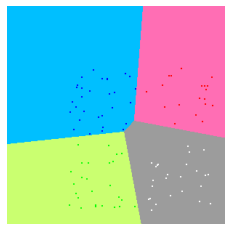


### Implementation of training procedure

With input data `x`, ground_truth `y`, and `model` as parameters, implement the gradient descent method to train your model and plot loss and accuracy vs training iterations

In [12]:
def train(x,
          y,
          model,
          loss_function=cross_entropy_loss,
          accuracy_function=accuracy,
          max_iteration=500,
          learning_rate=1):
    """
    Args:
       x (2-d list): List of Values with shape: [n_samples, n_channels]
       y (1-d list): List of integers with shape: [n_samples]
       model (Module): Linear model
       loss_function (callable): Loss function to use during training
       accuracy_function (callable): Function used for calculating training accuracy
       max_iteration (int): Number of epochs to train model for
       learning_rate (numeric): Step size of the gradient update
    """
    for i in range(max_iteration):
        #TODO compute y_hat and calculate the loss between y_hat and y as well as
        # the accuracy of y_hat w.r.t y.
        y_hat = model(x)
        loss = loss_function(y_hat, y)
        acc = accuracy_function(y_hat, y)

        #TODO Then You will need to calculate gradient for all parameters, and
        #do gradient descent for all the parameters.
        #The list of parameters can be easily obtained by calling
        #model.parameters() which is implemented above.
        model.zero_grad()
        for sample in x:
            for value in sample:
                if isinstance(value, Value):
                    value.grad = 0

        #Calculate gradients
        loss.backward()

        #Update weights and biases
        for parameter in model.parameters():
            parameter.data -= learning_rate * parameter.grad
            

        #Then plot the loss / accuracy vs iterations.
        if i % 20 == 19:
            print("iteration",i,"loss:",loss.data, "accuracy:",acc)
        ## record loss
        if i == 0 :
        # initialize L
            L = loss.data
            A = acc
        else:
            L = np.append(L,loss.data)
            A = np.append(A,acc)

    final_predictions = model(x)
    final_accuracy = accuracy_function(final_predictions, y)
    print(f"Final training accuracy: {final_accuracy:.2%}")
    
    ## Plot Loss and Accuracy
    fig0=plt.figure()
    plt.plot(L,'-')
    plt.xlabel('Iteration', fontsize=18)
    plt.ylabel('Loss', fontsize=16)
    plt.show()
    fig1=plt.figure(1)
    plt.plot(A,'-')
    plt.xlabel('Iteration', fontsize=18)
    plt.ylabel('Accuracy', fontsize=16)
    plt.show()


### Train the model

Load the data, format it, instantiate your model and start training!

(100, 2) (100,) [0 1 2 3]
iteration 19 loss: 0.569276567658956 accuracy: 0.96
iteration 39 loss: 0.41933110679994673 accuracy: 0.96
iteration 59 loss: 0.3485586977655465 accuracy: 0.97
iteration 79 loss: 0.30500731394165476 accuracy: 0.98
iteration 99 loss: 0.2746607020397763 accuracy: 0.98
iteration 119 loss: 0.2519116057137524 accuracy: 0.99
iteration 139 loss: 0.2340112384811345 accuracy: 0.99
iteration 159 loss: 0.21943039145241064 accuracy: 0.99
iteration 179 loss: 0.20724093872722008 accuracy: 0.99
iteration 199 loss: 0.19684239432216044 accuracy: 0.99
iteration 219 loss: 0.18782671359025757 accuracy: 0.99
iteration 239 loss: 0.17990560873839634 accuracy: 0.99
iteration 259 loss: 0.17286883716795992 accuracy: 0.99
iteration 279 loss: 0.16655897577858803 accuracy: 0.99
iteration 299 loss: 0.16085549333262608 accuracy: 0.99
iteration 319 loss: 0.15566432380677112 accuracy: 1.0
iteration 339 loss: 0.15091082785072288 accuracy: 1.0
iteration 359 loss: 0.1465349138969665 accuracy: 1.0

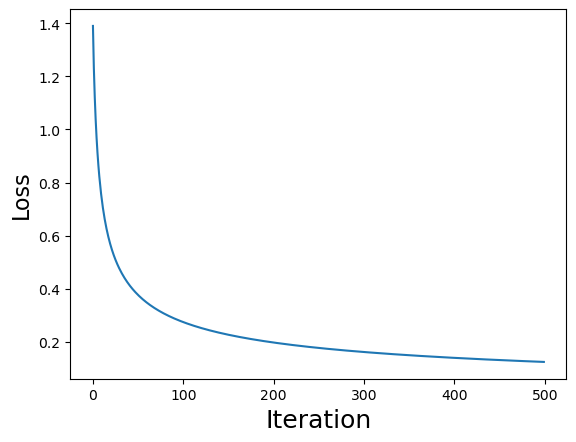

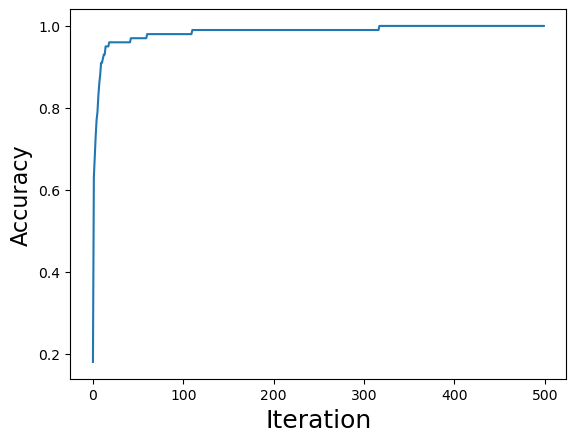

In [13]:
## Load Q3 Dataset
datapath = 'HW2_dataset/HW2_Q3_dataset/Q3_data.npz'
data = np.load(datapath)

## Load Data and Parse Shape Information
X = data['X']
Y = data['Y']
print(X.shape, Y.shape, np.unique(Y))
nin = X.shape[1]
nout = np.max(Y) + 1

## Initialize data using your Value class
x = [[Value(v) for v in sample] for sample in X]
y = [int(v) for v in Y]

## Initialize a Linear Model
linear_model = LinearLayer(nin, nout)

## Train the Model using Your Data
train(x, y, linear_model)

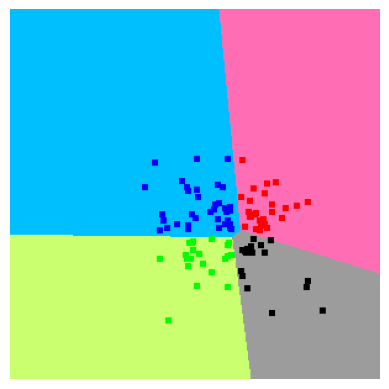

In [14]:
## Visualize learned decision boundaries
visualization(X, Y, linear_model)

## Question 4

### a) Is this dataset linear separable?
load the dataset for this question and train a linear model on this dataset and report the performance

In [15]:
## Load Q4 Dataset
datapath = 'HW2_dataset/HW2_Q4_dataset/Q4_data.npz'
data = np.load(datapath)

## Parse Data and Identify Dimensions
X = data['X']
Y = data['Y']
nin = X.shape[1]
nout = int(np.max(Y)) + 1

## Initialize data using your value class
x = [[Value(v) for v in sample] for sample in X]
y = [int(v) for v in Y]

iteration 19 loss: 0.3784203099675563 accuracy: 0.8
iteration 39 loss: 0.3585284399345305 accuracy: 0.8
iteration 59 loss: 0.3507490957439532 accuracy: 0.825
iteration 79 loss: 0.3463327387402485 accuracy: 0.825
iteration 99 loss: 0.3434528780884321 accuracy: 0.825
iteration 119 loss: 0.34143470519251057 accuracy: 0.825
iteration 139 loss: 0.3399556817259106 accuracy: 0.825
iteration 159 loss: 0.33883837761136815 accuracy: 0.825
iteration 179 loss: 0.3379757291958543 accuracy: 0.85
iteration 199 loss: 0.3372986551479705 accuracy: 0.85
iteration 219 loss: 0.33676030086914777 accuracy: 0.85
iteration 239 loss: 0.33632767502795397 accuracy: 0.85
iteration 259 loss: 0.3359768793427248 accuracy: 0.85
iteration 279 loss: 0.33569021881171845 accuracy: 0.85
iteration 299 loss: 0.33545436170940857 accuracy: 0.85
iteration 319 loss: 0.33525911979709666 accuracy: 0.85
iteration 339 loss: 0.33509661323660017 accuracy: 0.85
iteration 359 loss: 0.3349606840317041 accuracy: 0.85
iteration 379 loss: 0

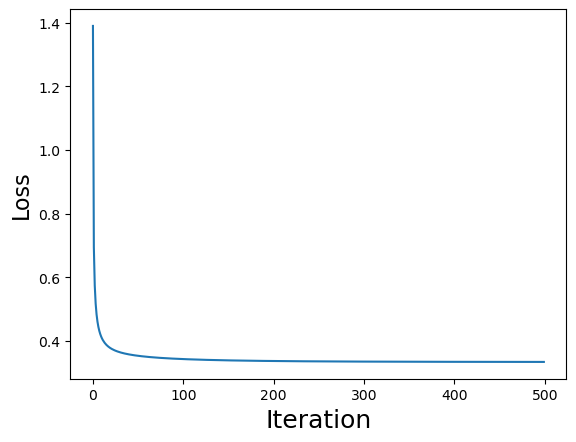

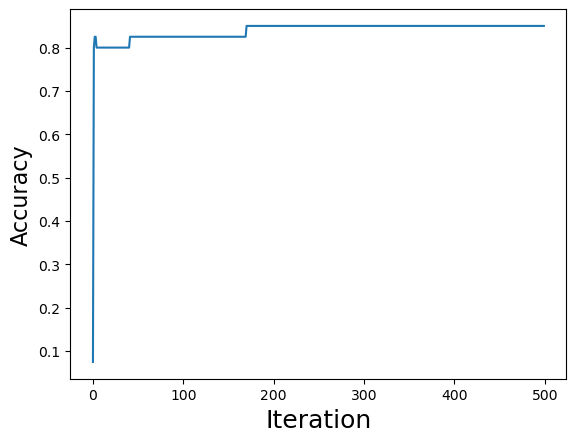

In [16]:
## Initialize Linear Model
linear_model = LinearLayer(nin, nout)

## Train Model
train(x, y, linear_model)

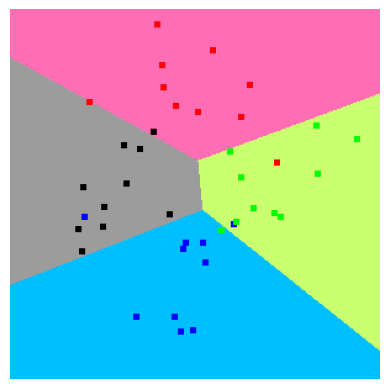

In [17]:
## Visualize Learned Decision Boundary
visualization(X, Y, linear_model)

### b) Implementation of Multi Layer Perceptron (MLP)

Implement a class `MLP` to add arbitrary layers. You will need to implement the forward function to return results `out` with `x` fed into the model.

In [20]:
class MLP(Module):

    """
    Multi Layer Perceptron
    """
    def __init__(self, dimensions):
        """
        Initialize multiple layers here in the list named self.linear_layers
        """
        assert isinstance(dimensions, list)
        assert len(dimensions) > 2
        self.linear_layers = []
        for i in range(len(dimensions) - 1):
            self.linear_layers.append(LinearLayer(dimensions[i], dimensions[i+1]))

    def __call__(self, x):
        """
        Args:
            x (2d-list): Two dimensional list of Values with shape [batch_size , nin]

        Returns:
            xout (2d-list): Two dimensional list of Values with shape [batch_size, nout]
        """
        for i, layer in enumerate(self.linear_layers):
            x = layer(x)

            if i < len(self.linear_layers) - 1:
                x = [
                    [value.relu() for value in sample]
                    for sample in x
                ]

        return x

    def parameters(self):
        """
        Get the parameters of each layer

        Args:
            None

        Returns:
            params (list of Values): Parameters of the MLP
        """
        return [p for layer in self.linear_layers for p in layer.parameters()]

    def zero_grad(self):
        """
        Zero out the gradient of each parameter
        """
        for p in self.parameters():
            p.grad = 0

Train your MLP model and visualize the decision boundary with ground truth points.

iteration 19 loss: 0.36835828869573867 accuracy: 0.8
iteration 39 loss: 0.3279622162027326 accuracy: 0.825
iteration 59 loss: 0.3127634971260317 accuracy: 0.825
iteration 79 loss: 0.2994590985827569 accuracy: 0.875
iteration 99 loss: 0.2866849853943176 accuracy: 0.875
iteration 119 loss: 0.27477423834030623 accuracy: 0.9
iteration 139 loss: 0.26361735224905786 accuracy: 0.9
iteration 159 loss: 0.254103657864177 accuracy: 0.9
iteration 179 loss: 0.2658556523349187 accuracy: 0.925
iteration 199 loss: 0.2576545096823667 accuracy: 0.925
iteration 219 loss: 0.24906254414078732 accuracy: 0.925
iteration 239 loss: 0.24021008116874398 accuracy: 0.925
iteration 259 loss: 0.2351794656981261 accuracy: 0.925
iteration 279 loss: 0.2308978378984317 accuracy: 0.925
iteration 299 loss: 0.2252325982646773 accuracy: 0.925
iteration 319 loss: 0.22286933775018403 accuracy: 0.925
iteration 339 loss: 0.22156995224559772 accuracy: 0.925
iteration 359 loss: 0.2142063182888442 accuracy: 0.925
iteration 379 los

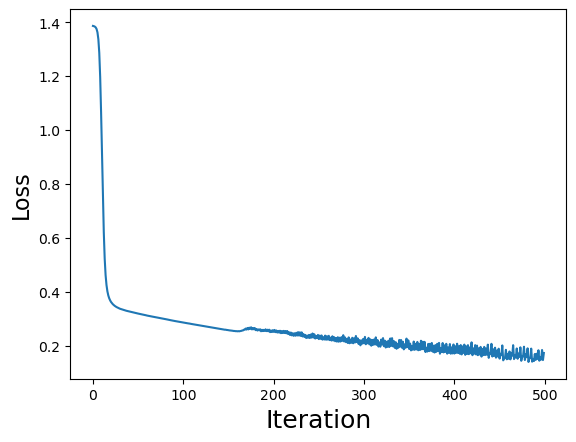

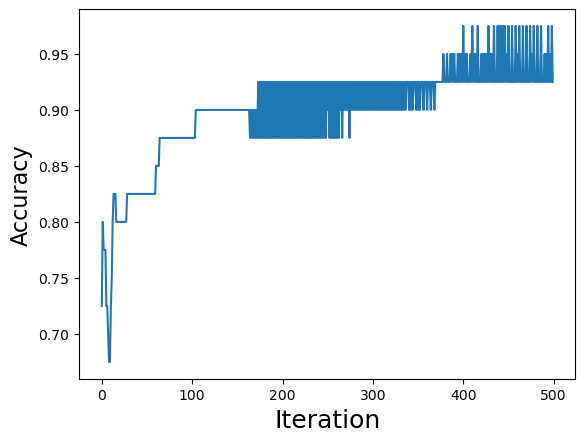

In [23]:
## Initialize MLP with Given Parameters
mlp_model = MLP([nin, 40, nout])

## Train the MLP
train(x, y, mlp_model)

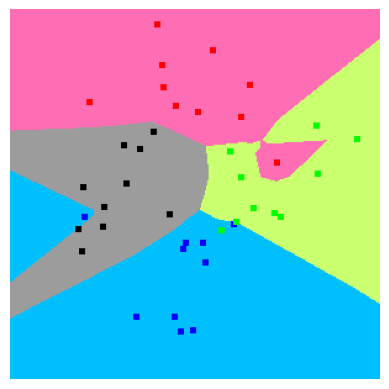

In [24]:
## Visualize Decision Boundaries
visualization(X, Y, mlp_model)

## Acknowledgement

The design of the auto grade structure are based on the work https://github.com/karpathy/micrograd